# Project 12: Understanding Convolution and Pooling

## Introduction

- In CNNs, the raw image is not directly passed to the output — instead, the network first **extracts features** using convolution and pooling
- **Convolution** applies a small filter (also called a kernel) over the image to detect patterns like edges, curves, or textures
- **Pooling** reduces the size of the feature map while keeping the most important information
- Two common pooling types are:
  - **Max Pooling** — picks the maximum value from each region
  - **Average Pooling** — takes the average value from each region
- In this project, these operations are applied manually on a real image to see what each filter does

## Task 1: Load a Sample Image

- A sample image is loaded from the **MNIST dataset** (a handwritten digit)
- This keeps the project consistent with Project 11 and avoids dealing with external image files
- The image is a 28×28 grayscale image

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

In [7]:
# Load MNIST and pick one sample image
(X_train, y_train), (_, _) = mnist.load_data()

In [8]:
# Pick digit '3' for a clear edge structure
idx = np.where(y_train == 3)[0][0]
image = X_train[idx].astype(np.float32)

In [9]:
print("Image shape:", image.shape)
print("Digit label:", y_train[idx])

Image shape: (28, 28)
Digit label: 3


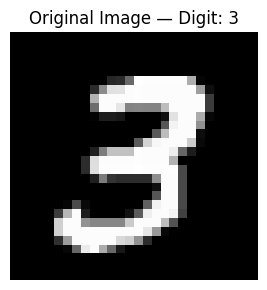

In [10]:
plt.figure(figsize=(3, 3))
plt.imshow(image, cmap='gray')
plt.title(f"Original Image — Digit: {y_train[idx]}")
plt.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Apply Convolution Filters and Pooling Operations

Three filters are applied manually using `scipy.ndimage.convolve`:

| Filter | Purpose |
|--------|---------|
| Edge Detection | Highlights the boundaries/outlines in the image |
| Sharpening | Makes the features appear more defined |
| Blur | Smooths the image, removes noise |

After convolution, both **Max Pooling** and **Average Pooling** are applied to the edge-detected feature map.

In [11]:
from scipy.ndimage import convolve

In [12]:
# Define filters (kernels)
edge_filter = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]], dtype=np.float32)

sharpen_filter = np.array([[ 0, -1,  0],
                             [-1,  5, -1],
                             [ 0, -1,  0]], dtype=np.float32)

blur_filter = np.ones((3, 3), dtype=np.float32) / 9.0

In [13]:
# Apply convolution
edge_map = convolve(image, edge_filter)
sharpen_map = convolve(image, sharpen_filter)
blur_map = convolve(image, blur_filter)

In [14]:
# Clip values to valid range
edge_map = np.clip(edge_map,    0, 255)
sharpen_map = np.clip(sharpen_map, 0, 255)
blur_map = np.clip(blur_map,    0, 255)

In [15]:
print("Convolution applied — shapes:", edge_map.shape, sharpen_map.shape, blur_map.shape)

Convolution applied — shapes: (28, 28) (28, 28) (28, 28)


In [16]:
# Manual Max Pooling and Average Pooling (2x2, stride 2)
def max_pool(feature_map, pool_size=2):
    h, w = feature_map.shape
    out_h, out_w = h // pool_size, w // pool_size
    output = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            region = feature_map[i*pool_size:(i+1)*pool_size,
                                  j*pool_size:(j+1)*pool_size]
            output[i, j] = np.max(region)
    return output

def avg_pool(feature_map, pool_size=2):
    h, w = feature_map.shape
    out_h, out_w = h // pool_size, w // pool_size
    output = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            region = feature_map[i*pool_size:(i+1)*pool_size,
                                  j*pool_size:(j+1)*pool_size]
            output[i, j] = np.mean(region)
    return output

max_pooled = max_pool(edge_map)
avg_pooled = avg_pool(edge_map)

In [17]:
print("Original size:", edge_map.shape)
print("After Max Pool:", max_pooled.shape)
print("After Avg Pool:", avg_pooled.shape)

Original size: (28, 28)
After Max Pool: (14, 14)
After Avg Pool: (14, 14)


## Task 3: Visualize and Compare the Original Image and Feature Maps

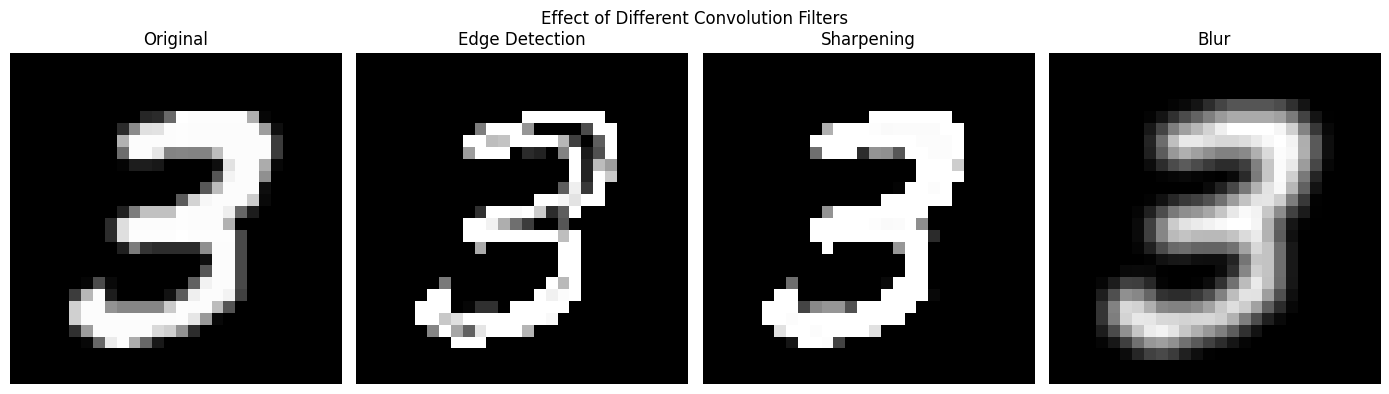

In [18]:
# Visualize original vs convolution results
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(image,       cmap='gray'); axes[0].set_title('Original')
axes[1].imshow(edge_map,    cmap='gray'); axes[1].set_title('Edge Detection')
axes[2].imshow(sharpen_map, cmap='gray'); axes[2].set_title('Sharpening')
axes[3].imshow(blur_map,    cmap='gray'); axes[3].set_title('Blur')

for ax in axes:
    ax.axis('off')

plt.suptitle('Effect of Different Convolution Filters', fontsize=12)
plt.tight_layout()
plt.show()

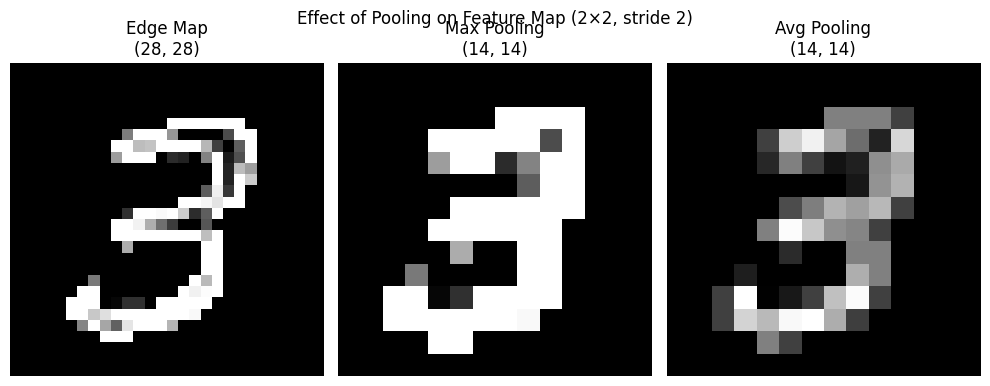

In [19]:
# Visualize pooling results
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

axes[0].imshow(edge_map,    cmap='gray'); axes[0].set_title(f'Edge Map\n{edge_map.shape}')
axes[1].imshow(max_pooled,  cmap='gray'); axes[1].set_title(f'Max Pooling\n{max_pooled.shape}')
axes[2].imshow(avg_pooled,  cmap='gray'); axes[2].set_title(f'Avg Pooling\n{avg_pooled.shape}')

for ax in axes:
    ax.axis('off')

plt.suptitle('Effect of Pooling on Feature Map (2×2, stride 2)', fontsize=12)
plt.tight_layout()
plt.show()

## Conclusion

- A handwritten digit from the MNIST dataset was used as the sample image
- Three convolution filters were applied manually:
  - **Edge Detection** clearly highlighted the outlines of the digit by detecting areas where pixel intensity changes sharply
  - **Sharpening** made the features more defined and pronounced
  - **Blur** smoothed the image and reduced fine details
- **Max Pooling** retained the strongest features (brightest regions) while reducing the image size from 28×28 to 14×14
- **Average Pooling** gave a smoother, more uniform reduction of the same feature map
- This experiment shows why CNNs use convolution + pooling layers — convolution extracts useful features, and pooling reduces size while keeping important information, making the network more efficient